<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/CIA_y_Matching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Independencia condicional (CIA) y matching

Este notebook acompaña las slides del Día 6. Ejemplos:

1. **Rappi** (datos simulados del libro *Econometrics with Simulations*): conocemos el efecto verdadero, así que podemos juzgar cada estimador.
2. **Dale y Krueger (2002)**: el ejemplo de la matriz de universidades, a mano.
3. **Happiness on Tap** (Devoto, Duflo, Dupas, Parienté y Pons, 2012): extracto de un experimento real. Las variables fueron modificadas, así que **no replica el paper**.
4. **LaLonde (1986) y Dehejia–Wahba (1999)**: ¿recupera el matching el efecto de un experimento si reemplazamos el grupo de control?

Plan:
1. Matching exacto por segmentos y su relación con la regresión
2. Dale y Krueger
3. Vecino más cercano: la discrepancia, el sesgo y su corrección
4. Errores estándar de Abadie–Imbens
5. Propensity score matching: soporte común, trimming y balance
6. Happiness on Tap
7. NSW / Dehejia–Wahba
8. Ejercicios

## 0. Preparación

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from scipy.spatial import cKDTree

warnings.filterwarnings('ignore')
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})

BASE = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'
def leer(nombre):
    # primero busca el archivo en la carpeta datos/ (si se corre desde el repo); si no, lo baja de GitHub
    import os
    ruta = os.path.join('datos', nombre)
    return pd.read_csv(ruta if os.path.exists(ruta) else BASE + nombre)

EFECTO_VERDADERO = -1.5   # solo lo conocemos porque los datos de Rappi son simulados

## 1. Matching exacto por segmentos (Rappi)

Un analista de Rappi compara los clientes que tuvieron una **entrega demorada** (`late = 1`) con los que no (`late = 0`) y mira cuántos pedidos hicieron en los 30 días siguientes (`orders`). Los clientes se agrupan en cuatro **segmentos** según zona y horario:

- **A**: centro, hora pico (los más expuestos a demoras y los que más piden);
- **B**: centro, fuera de pico;
- **C**: residencial, hora pico;
- **D**: residencial, fuera de pico (casi nunca demorados, los que menos piden).

**Los datos son simulados**: son los mismos que muestra el dashboard *Matching por segmentos* del libro. El escenario es estilizado; no son datos de Rappi.

In [2]:
seg = leer('matching_segments.csv')
seg['segment'] = seg['segment'].astype('category')   # para que patsy/statsmodels lo traten como categórica
print(seg.shape)
seg.head()

(4000, 3)


,segment,late,orders
0,C,0,7.214
1,C,0,6.745
2,A,0,8.211
3,A,0,10.890
4,C,0,2.547


In [3]:
medias = seg.groupby('late').orders.mean()
ingenuo = medias[1] - medias[0]
print(medias.round(2).to_string())
print(f'\nDiferencia ingenua: {ingenuo:+.2f}   (efecto verdadero: {EFECTO_VERDADERO})')

late
0    5.62
1    6.04

Diferencia ingenua: +0.41   (efecto verdadero: -1.5)


La comparación ingenua dice que las demoras **aumentan** los pedidos. El problema: las demoras caen más en el segmento A, que pide mucho de todos modos. Veamos qué pasa *dentro* de cada segmento.

### 1.1 La tabla de matching

Un `groupby` por segmento y grupo arma la tabla: medias y cantidades de demorados y no demorados, la diferencia $\hat\delta_x$ dentro de cada segmento y su peso en el ATT ($n_{1x}/n_1$) y en el ATE ($n_x/n$). Los pesos se calculan **solo sobre segmentos con soporte común**: donde hay clientes de los dos grupos.

In [4]:
def tabla_matching(df, y='orders', t='late', celda='segment'):
    g = df.groupby([celda, t])[y].agg(['mean', 'size']).unstack(t)
    g.columns = ['media_control', 'media_trat', 'n_control', 'n_trat']
    g = g[['media_trat', 'n_trat', 'media_control', 'n_control']]
    soporte = (g.n_trat > 0) & (g.n_control > 0)                 # soporte común: hay de los dos grupos
    g['delta'] = (g.media_trat - g.media_control).where(soporte)
    g['peso_att'] = (g.n_trat / g.n_trat[soporte].sum()).where(soporte, 0)
    n_x = g.n_trat + g.n_control
    g['peso_ate'] = (n_x / n_x[soporte].sum()).where(soporte, 0)
    return g

tabla = tabla_matching(seg)
att = (tabla.peso_att * tabla.delta).sum()
ate = (tabla.peso_ate * tabla.delta).sum()
display(tabla)
print(f'ATT (matching exacto) = {att:.2f}     ATE = {ate:.2f}     ingenuo = {ingenuo:+.2f}     verdadero = {EFECTO_VERDADERO}')

,media_trat,n_trat,media_control,n_control,delta,peso_att,peso_ate
segment,,,,,,,
A,7.527,555,9.090,441,-1.564,0.498,0.249
B,5.534,315,6.900,730,-1.366,0.283,0.261
C,3.603,193,5.068,786,-1.465,0.173,0.245
D,2.179,52,3.435,928,-1.256,0.047,0.245


ATT (matching exacto) = -1.48     ATE = -1.41     ingenuo = +0.41     verdadero = -1.5


**Cómo leerlo.** Dentro de cada segmento los demorados piden **menos** que los no demorados (alrededor de −1,5 en todos), y el promedio ponderado cae cerca del efecto verdadero. La comparación ingenua tenía el signo equivocado. La mitad de los demorados está en el segmento A: comparar dentro de cada segmento neutraliza esa ventaja.

### 1.2 ¿Qué pasa si falta soporte común?

Supongamos que ningún cliente del segmento A hubiera tenido una entrega a tiempo. Simulamos esa situación eliminando a los no demorados de A: la fila de A deja de tener contrafáctico.

In [5]:
seg_sin_soporte = seg[~((seg.segment == 'A') & (seg.late == 0))]
t2 = tabla_matching(seg_sin_soporte)
display(t2)
print(f"ATT estimado sin el segmento A: {(t2.peso_att * t2.delta).sum():.2f}")

,media_trat,n_trat,media_control,n_control,delta,peso_att,peso_ate
segment,,,,,,,
A,7.527,555.0,NaN,NaN,NaN,0.000,0.000
B,5.534,315.0,6.900,730.0,-1.366,0.562,0.348
C,3.603,193.0,5.068,786.0,-1.465,0.345,0.326
D,2.179,52.0,3.435,928.0,-1.256,0.093,0.326


ATT estimado sin el segmento A: -1.39


El estimador **descarta** el segmento A y estima el ATT solo para los demorados de B, C y D. Acá los efectos son parecidos entre segmentos, así que no se nota; con efectos distintos, **la pregunta cambia**.

### 1.3 La regresión con dummies, y por qué con efectos heterogéneos no coincide

Con un conjunto completo de dummies de segmento, la regresión también compara dentro de cada segmento. Repetimos con una segunda muestra donde el efecto **depende del segmento** (los clientes del centro en hora pico pierden más pedidos con una demora, y los del segmento D no pierden nada).

In [6]:
def comparar(df):
    tab = tabla_matching(df)
    att = (tab.peso_att * tab.delta).sum()
    ate = (tab.peso_ate * tab.delta).sum()
    mco = smf.ols('orders ~ late + C(segment)', data=df).fit(cov_type='HC1')
    inter = smf.ols('orders ~ late * C(segment)', data=df).fit()
    tr = df[df.late == 1]
    att_inter = (inter.predict(tr.assign(late=1)) - inter.predict(tr.assign(late=0))).mean()
    ing = df[df.late == 1].orders.mean() - df[df.late == 0].orders.mean()
    return pd.Series({'Ingenuo': ing, 'Matching (ATT)': att, 'ATE': ate,
                      'MCO con dummies': mco.params['late'], 'MCO interactuado (ATT)': att_inter})

seg_het = leer('matching_segments_het.csv')
seg_het['segment'] = seg_het['segment'].astype('category')
res = pd.DataFrame({'Efecto igual en todos': comparar(seg), 'Efecto distinto por segmento': comparar(seg_het)})
res

,Efecto igual en todos,Efecto distinto por segmento
Ingenuo,0.414,-0.808
Matching (ATT),-1.477,-2.854
ATE,-1.413,-1.694
MCO con dummies,-1.453,-2.434
MCO interactuado (ATT),-1.477,-2.854


**Cómo leerlo.** Con el mismo efecto en todos los segmentos, matching y MCO coinciden. Con efectos distintos:

- el **matching** y la regresión **interactuada** dan exactamente el mismo ATT;
- el **MCO con dummies** da un número distinto: no está mal estimado, pondera los segmentos de otra manera.

Los pesos son:

| Estimador | Peso del segmento $x$ |
|---|---|
| ATE | $P(X=x)$ |
| ATT (matching) | $P(X=x \mid T=1)$ |
| MCO con dummies | $\propto P(X=x)\,p_x(1-p_x)$, con $p_x=P(T=1\mid X=x)$ |

,delta_x,p_x,peso ATE,peso ATT,peso MCO
segment,,,,,
A,-4.059,0.562,0.252,0.543,0.399
B,-2.046,0.276,0.243,0.257,0.313
C,-0.815,0.170,0.245,0.159,0.222
D,0.106,0.041,0.260,0.041,0.066


Suma ponderada con los pesos de MCO: -2.434   (coincide con el coeficiente de MCO)


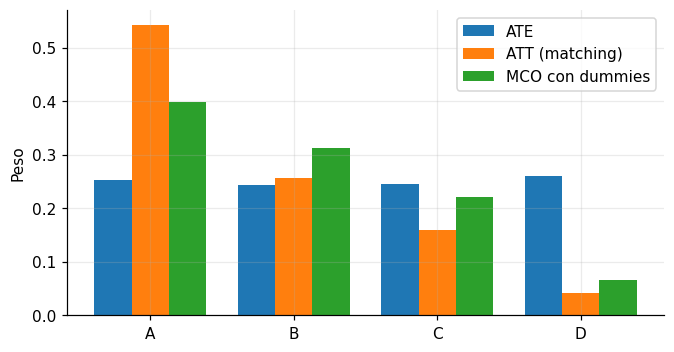

In [7]:
tab = tabla_matching(seg_het)
n_x = tab.n_trat + tab.n_control
p_x = tab.n_trat / n_x
w_mco = n_x * p_x * (1 - p_x); w_mco = w_mco / w_mco.sum()
pesos = pd.DataFrame({'delta_x': tab.delta, 'p_x': p_x, 'peso ATE': tab.peso_ate, 'peso ATT': tab.peso_att, 'peso MCO': w_mco})
display(pesos)
print('Suma ponderada con los pesos de MCO:', round((w_mco * tab.delta).sum(), 3), '  (coincide con el coeficiente de MCO)')
fig, ax = plt.subplots(figsize=(7, 3.6)); x = np.arange(4); w = .26
ax.bar(x - w, pesos['peso ATE'], w, label='ATE'); ax.bar(x, pesos['peso ATT'], w, label='ATT (matching)'); ax.bar(x + w, pesos['peso MCO'], w, label='MCO con dummies')
ax.set_xticks(x); ax.set_xticklabels(pesos.index); ax.set_ylabel('Peso'); ax.legend(); plt.show()

El ATT pone casi la mitad del peso en el segmento A (donde están los demorados); el MCO, en el que más varía el tratamiento ($p_x$ cerca de 0,5); el ATE reparte parejo. Como $\delta_x$ es muy distinto entre segmentos, los tres números difieren. **¿Cuál conviene?** Depende de la pregunta: el ATT responde cuánto costaron las demoras que efectivamente ocurrieron; el ATE, qué pasaría si todos las tuvieran; el MCO con dummies, ninguna de las dos.

## 2. Dale y Krueger (2002), versión simplificada

¿Vale la pena estudiar en una universidad más selectiva? Dale y Krueger agrupan a los estudiantes según el **conjunto de universidades que los admitieron** y comparan, dentro de cada grupo, a quienes eligieron una privada (más selectiva) con quienes eligieron una pública. La matriz de la slide, con ingresos de 1996 en miles de dólares:

In [8]:
dk = pd.DataFrame({
    'estudiante': range(1, 10),
    'grupo': list('AAABBCCDD'),
    'privada': [1, 1, 0, 1, 0, 1, 1, 0, 0],
    'ingreso': [110, 100, 110, 60, 30, 115, 75, 90, 60],
})
dk

,estudiante,grupo,privada,ingreso
0,1,A,1,110
1,2,A,1,100
2,3,A,0,110
3,4,B,1,60
4,5,B,0,30
5,6,C,1,115
6,7,C,1,75
7,8,D,0,90
8,9,D,0,60


In [9]:
ing_bruta = dk[dk.privada == 1].ingreso.mean() - dk[dk.privada == 0].ingreso.mean()
print(f'Sin matchear: privada {dk[dk.privada==1].ingreso.mean():.0f} vs pública {dk[dk.privada==0].ingreso.mean():.1f}  ->  diferencia = {ing_bruta:.1f}')

tabla_dk = tabla_matching(dk, y='ingreso', t='privada', celda='grupo')
display(tabla_dk)

# Pesos "por tamaño del grupo" (ATE entre A y B) y "por privadas" (ATT)
ate_dk = (tabla_dk.peso_ate * tabla_dk.delta).sum(); att_dk = (tabla_dk.peso_att * tabla_dk.delta).sum()
print(f'\nMatching ponderando por tamaño del grupo (ATE entre A y B): {ate_dk:.1f}')
print(f'Matching ponderando por estudiantes en privadas (ATT):       {att_dk:.1f}')

Sin matchear: privada 92 vs pública 72.5  ->  diferencia = 19.5


,media_trat,n_trat,media_control,n_control,delta,peso_att,peso_ate
grupo,,,,,,,
A,105.0,2.0,110.0,1.0,-5.0,0.667,0.6
B,60.0,1.0,30.0,1.0,30.0,0.333,0.4
C,95.0,2.0,NaN,NaN,NaN,0.000,0.0
D,NaN,NaN,75.0,2.0,NaN,0.000,0.0



Matching ponderando por tamaño del grupo (ATE entre A y B): 9.0
Matching ponderando por estudiantes en privadas (ATT):       6.7


**Cómo leerlo.** La ventaja bruta de 19,5 mil dólares se reduce a menos de la mitad (9,0 o 6,7 según el peso). Los grupos C (solo privadas) y D (solo públicas) **se descartan** porque no tienen soporte común: en C no hay quién sirva de contrafáctico de la privada. Y el resultado depende de la pregunta: ATE o ATT.

## 3. Variables continuas: vecino más cercano

Ahora las características son continuas: frecuencia de pedidos (`order_freq`), distancia al centro (`dist_center_km`), proporción de pedidos en hora pico (`peak_share_pct`) y antigüedad (`tenure_months`). Hay 1.000 clientes demorados y 4.000 sin demora; los pedidos esperados dependen de las características de forma levemente curva. **El efecto verdadero es −1,5 para todos.**

In [10]:
cont = leer('matching_continuous.csv')
COVS = ['order_freq', 'dist_center_km', 'peak_share_pct', 'tenure_months']
print(cont.late.value_counts().rename({0: 'sin demora', 1: 'demorados'}).to_string())
cont.groupby('late')[COVS + ['orders']].mean().rename(index={0: 'sin demora', 1: 'demorados'})

late
sin demora    4000
demorados     1000


,order_freq,dist_center_km,peak_share_pct,tenure_months,orders
late,,,,,
sin demora,8.805,10.380,38.434,22.657,5.776
demorados,10.314,8.681,46.164,28.424,5.506


### 3.1 Paso 1: el vecino más cercano

Estandarizamos cada característica (dividiendo por su desvío estándar) y, para cada demorado, buscamos el cliente sin demora más cercano con un árbol k-d (`cKDTree`), **con reemplazo**. Guardamos `K`: cuántas veces se usa cada control (lo necesitaremos para el error estándar).

In [11]:
X = cont[COVS].to_numpy()
Xs = (X - X.mean(0)) / X.std(0)
t = cont.late.to_numpy() == 1
Xt, Xc = Xs[t], Xs[~t]
yt, yc = cont.orders.to_numpy()[t], cont.orders.to_numpy()[~t]

arbol = cKDTree(Xc)
dist, j = arbol.query(Xt, k=1)                       # j[i] = índice (entre controles) del match de i
K = np.bincount(j, minlength=len(yc)).astype(float)

tau_simple = np.mean(yt - yc[j])
print(f'ATT por matching simple: {tau_simple:.3f}   (verdadero: {EFECTO_VERDADERO})')
print(f'Distancia promedio al match (en desvíos estándar): {dist.mean():.2f}')
print(f'Controles nunca usados: {(K == 0).mean():.0%};  máximo de usos de un mismo control: {int(K.max())}')
dif = pd.DataFrame(np.abs(X[t] - X[~t][j]), columns=COVS).median().rename('diferencia mediana al match')
dif.to_frame()

ATT por matching simple: -1.311   (verdadero: -1.5)
Distancia promedio al match (en desvíos estándar): 0.38
Controles nunca usados: 81%;  máximo de usos de un mismo control: 6


,diferencia mediana al match
order_freq,0.37
dist_center_km,0.42
peak_share_pct,1.90
tenure_months,1.50


Con cuatro características el vecino más cercano **no es idéntico**: queda una discrepancia $U_i=X_{j(i)}-X_i$ en cada una. Esa discrepancia genera el sesgo.

### 3.2 La maldición de la dimensionalidad

¿Cuánto se achica la discrepancia con más datos? Simulamos clientes con $k$ características normales independientes, con 4 controles por demorado, y medimos la distancia promedio al vecino más cercano. Teoría (Abadie e Imbens, 2006): $\lVert U_i\rVert\propto N^{-1/k}$.

,k = 1,k = 2,k = 4,k = 8
N1 (demorados),,,,
100,5.125e-03,0.126,0.532,1.563
300,2.139e-03,0.063,0.423,1.395
1000,6.798e-04,0.037,0.332,1.161
3000,2.897e-04,0.024,0.256,1.028


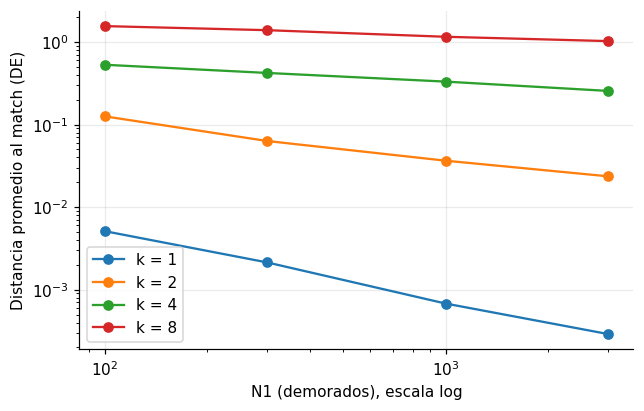

Pendiente log-log estimada (teoría: -1/k):
  k=1: -0.857  vs  -1.0
  k=2: -0.488  vs  -0.5
  k=4: -0.213  vs  -0.25
  k=8: -0.126  vs  -0.125


In [12]:
rng = np.random.default_rng(0)
Ns = [100, 300, 1000, 3000]
res_d = {}
for k in [1, 2, 4, 8]:
    fila = []
    for n1 in Ns:
        xt = rng.normal(size=(n1, k)); xc = rng.normal(size=(4 * n1, k))
        fila.append(cKDTree(xc).query(xt)[0].mean())
    res_d[f'k = {k}'] = fila
res_d = pd.DataFrame(res_d, index=Ns); res_d.index.name = 'N1 (demorados)'
display(res_d)
ax = res_d.plot(logx=True, logy=True, marker='o', figsize=(6.5, 4))
ax.set_ylabel('Distancia promedio al match (DE)'); ax.set_xlabel('N1 (demorados), escala log'); plt.show()
print('Pendiente log-log estimada (teoría: -1/k):')
for k in [1, 2, 4, 8]:
    print(f'  k={k}:', round(np.polyfit(np.log(Ns), np.log(res_d[f"k = {k}"]), 1)[0], 3), ' vs ', round(-1 / k, 3))

**Cómo leerlo.** Con $k=1$ la distancia cae rápido. Con $k=8$ la distancia promedio ronda 1,6 desvíos con 100 demorados y **todavía 1,0** con 3.000: treinta veces más datos apenas la redujeron un tercio. Duplicar los datos multiplica la discrepancia por $2^{-1/k}$ (0,5 con $k=1$; 0,92 con $k=8$): reducirla a la mitad exige $2^k$ veces más datos (256 con $k=8$).

### 3.3 ¿Más datos resuelven el sesgo? (simulación de cobertura)

Si $\mu_0(x)=E[Y(0)\mid X=x]$ cambia con $x$, cada par arrastra un error $\mu_0(X_i)-\mu_0(X_{j(i)})$. El sesgo del matching es $O(N^{-1/k})$, mientras el ruido es $O(N^{-1/2})$: con $k\ge2$ el sesgo domina cuando $N$ crece. Verificamos con una simulación mínima: $k=8$ características $N(0,1)$ en los controles, $N(0.5/\sqrt k\cdot\mathbf 1,\,I)$ en los demorados (hay selección), $\mu_0(x)=\sum_k x_k$ (lineal), efecto $-1.5$, ruido $N(0,1)$ y 4 controles por demorado. Primero necesitamos un estimador con errores estándar de Abadie–Imbens y la corrección de sesgo.

In [13]:
def att_matching(yt, yc, Xt, Xc, corregir=False):
    # ATT por vecino más cercano (1 match, con reemplazo), con corrección de sesgo opcional.
    # Devuelve (estimación, error estándar de Abadie-Imbens, K).
    arbol = cKDTree(Xc)
    j = arbol.query(Xt, k=1)[1]
    K = np.bincount(j, minlength=len(yc)).astype(float)
    if corregir:
        usados = K > 0; w = np.sqrt(K[usados])
        Dc = np.column_stack([np.ones(len(Xc)), Xc]); Dt = np.column_stack([np.ones(len(Xt)), Xt])
        beta = np.linalg.lstsq(Dc[usados] * w[:, None], yc[usados] * w, rcond=None)[0]   # MCP con pesos K
        y0 = yc[j] + Dt @ beta - Dc[j] @ beta
    else:
        y0 = yc[j]
    tau = np.mean(yt - y0)
    # varianza condicional de cada control: comparándolo con su vecino más cercano entre los controles
    nn2 = arbol.query(Xc, k=2)[1][:, 1]
    sig2 = 0.5 * (yc - yc[nn2]) ** 2
    se = np.sqrt((np.sum((yt - y0 - tau) ** 2) + np.sum(K * (K - 1) * sig2)) / len(yt) ** 2)
    return tau, se, K

def simular_cobertura(k, n1, reps=200, seed=1):
    rng = np.random.default_rng(seed)
    out = {'simple': [], 'corregido': []}
    for _ in range(reps):
        xt = rng.normal(0.5 / np.sqrt(k), 1, size=(n1, k)); xc = rng.normal(0, 1, size=(4 * n1, k))
        yt = xt.sum(1) + EFECTO_VERDADERO + rng.normal(size=n1); yc = xc.sum(1) + rng.normal(size=4 * n1)
        for nombre, corr in [('simple', False), ('corregido', True)]:
            tau, se, _ = att_matching(yt, yc, xt, xc, corr)
            out[nombre].append((tau, se))
    filas = []
    for nombre, v in out.items():
        v = np.array(v); cubre = np.abs(v[:, 0] - EFECTO_VERDADERO) <= 1.96 * v[:, 1]
        filas.append({'estimador': nombre, 'k': k, 'N1': n1, 'media': v[:, 0].mean(), 'sesgo': v[:, 0].mean() - EFECTO_VERDADERO,
                      'DE': v[:, 0].std(), 'cobertura IC 95%': cubre.mean()})
    return filas

filas = []
for n1 in [100, 300, 1000]:
    filas += simular_cobertura(k=8, n1=n1, reps=150)
pd.DataFrame(filas).set_index(['estimador', 'N1']).sort_index()

k  media  sesgo     DE  cobertura IC 95%
estimador N1                                            
corregido 100   8 -1.499  0.001  0.162             0.967
          300   8 -1.486  0.014  0.094             0.940
          1000  8 -1.507 -0.007  0.053             0.940
simple    100   8 -1.081  0.419  0.206             0.567
          300   8 -1.157  0.343  0.125             0.200
          1000  8 -1.253  0.247  0.065             0.027

**Cómo leerlo.** Con $k=8$, la cobertura del matching **simple** cae a medida que $N_1$ crece: **más datos empeoran los intervalos**, porque el sesgo se achica más lento que el ruido. El matching con **corrección de sesgo**, con los mismos matches, mantiene la cobertura cerca de 95%.

### 3.4 Paso 2: corrección de sesgo en la muestra de Rappi (Abadie e Imbens, 2011)

Estimamos una regresión lineal de los pedidos sobre las características con los clientes sin demora, y ajustamos cada par por $\hat\mu_0(X_i)-\hat\mu_0(X_{j(i)})$. Como en el dashboard, la regresión se estima sobre los controles usados como match, cada uno ponderado por `K`.

In [14]:
tau_s, se_s, K_s = att_matching(yt, yc, Xs[t], Xs[~t], corregir=False)
tau_c, se_c, _ = att_matching(yt, yc, Xs[t], Xs[~t], corregir=True)

# Imputación por regresión (solo la regresión), para comparar
Dc = np.column_stack([np.ones(len(Xc)), Xc]); Dt = np.column_stack([np.ones(len(Xt)), Xt])
beta_all = np.linalg.lstsq(Dc, yc, rcond=None)[0]
tau_r = np.mean(yt - Dt @ beta_all)

res = pd.DataFrame({'estimación': [tau_s, tau_c, tau_r], 'error estándar (AI)': [se_s, se_c, np.nan]},
                   index=['Matching simple', 'Matching con corrección de sesgo', 'Imputación por regresión'])
res['IC 95% inf.'] = res['estimación'] - 1.96 * res['error estándar (AI)']; res['IC 95% sup.'] = res['estimación'] + 1.96 * res['error estándar (AI)']
res

,estimación,error estándar (AI),IC 95% inf.,IC 95% sup.
Matching simple,-1.311,0.101,-1.508,-1.113
Matching con corrección de sesgo,-1.429,0.099,-1.624,-1.234
Imputación por regresión,-1.098,NaN,NaN,NaN


**Cómo leerlo.** Compará cada intervalo con el efecto verdadero (−1,5). En **una sola muestra** cualquier intervalo puede fallar: lo que importa es lo que vimos en la simulación de 3.3 (muchas muestras).

### 3.5 Errores estándar: por qué *no* usar el bootstrap

El bootstrap habitual **no es válido** para el matching por vecino más cercano (Abadie e Imbens, 2008). La varianza analítica del ATT con un match suma dos partes: la dispersión de las diferencias dentro de cada par y un término extra por los controles reutilizados, $K_j(K_j-1)\hat\sigma^2(X_j)$. Es lo que implementa `att_matching`. Veamos cuánto pesa el segundo término:

In [15]:
arbol = cKDTree(Xc); nn2 = arbol.query(Xc, k=2)[1][:, 1]; sig2 = 0.5 * (yc - yc[nn2]) ** 2
parte_pares = np.sum((yt - yc[j] - tau_simple) ** 2); parte_reuso = np.sum(K * (K - 1) * sig2)
print(f'Suma de cuadrados de las diferencias dentro de los pares: {parte_pares:,.0f}')
print(f'Término por reutilización de controles:                   {parte_reuso:,.0f}  ({parte_reuso/(parte_pares+parte_reuso):.0%} del total)')

Suma de cuadrados de las diferencias dentro de los pares: 7,855
Término por reutilización de controles:                   2,261  (22% del total)


### Verificación cruzada con `causalinference`

El paquete `causalinference` implementa el mismo estimador (matchea sobre las características estandarizadas y corrige el sesgo). Las estimaciones puntuales deberían coincidir con las nuestras; los errores estándar pueden diferir porque el paquete estima las varianzas condicionales de otra manera.

In [16]:
try:
    from causalinference import CausalModel
except ImportError:
    try:
        %pip install -q causalinference
        from causalinference import CausalModel
    except Exception as e:
        CausalModel = None; print('causalinference no disponible:', type(e).__name__)

if CausalModel is not None:
    for corr in (False, True):
        cm = CausalModel(cont.orders.to_numpy(), cont.late.to_numpy(), X)
        cm.est_via_matching(matches=1, bias_adj=corr)
        print(f"bias_adj={corr!s:5}:  ATT = {cm.estimates['matching']['att']:.3f}  (EE {cm.estimates['matching']['att_se']:.3f})")
    print(f'Nuestros: simple = {tau_s:.3f}, corregido = {tau_c:.3f}')

bias_adj=False:  ATT = -1.311  (EE 0.142)
bias_adj=True :  ATT = -1.429  (EE 0.141)
Nuestros: simple = -1.311, corregido = -1.429


## 4. Propensity score matching

Ahora resumimos las características en **un solo número**, la probabilidad estimada de demora $e(X)=P(T=1\mid X)$. Los datos tienen 3.000 clientes con cinco características: ubicación en el centro (`center`), proporción de pedidos en hora pico (`peak_share_pct`), frecuencia de pedidos (`order_freq`), antigüedad (`tenure_months`) y ticket promedio (`basket_usd`). La demora depende de las tres primeras y de la **interacción** centro × hora pico, con selección fuerte.

La columna `true_effect` trae el efecto verdadero para cada cliente (efecto heterogéneo). Existe solo porque los datos son simulados y la usamos únicamente para evaluar.

In [17]:
ps = leer('matching_psm.csv')
ps['log_freq'] = np.log(ps.order_freq)           # la frecuencia es asimétrica: entra en logs
ps['peak'] = ps.peak_share_pct / 100
print(f'Clientes demorados: {ps.late.sum()} de {len(ps)}')
print(f"ATT verdadero (todos los demorados): {ps.loc[ps.late == 1, 'true_effect'].mean():.2f}")
ps.head()

Clientes demorados: 895 de 3000
ATT verdadero (todos los demorados): -1.87


,center,peak_share_pct,order_freq,tenure_months,basket_usd,late,orders,true_effect,log_freq,peak
0,0,28.5,2.44,29.4,16.48,0,2.721,0.000,0.892,0.285
1,1,13.2,9.08,76.4,28.29,0,4.478,-1.493,2.206,0.132
2,1,6.4,2.96,6.9,17.65,0,1.301,0.000,1.085,0.064
3,0,7.3,8.56,5.2,9.60,0,5.114,-1.227,2.147,0.073
4,1,65.0,4.86,31.5,14.11,1,4.077,-2.298,1.581,0.650


### 4.1 Paso 1: el modelo del score

Estimamos dos logits: uno **correcto** (con la interacción centro × hora pico) y uno **mal especificado** (sin ella).

In [18]:
f_correcto = 'late ~ center * peak + log_freq + tenure_months + basket_usd'
f_mal = 'late ~ center + peak + log_freq + tenure_months + basket_usd'
modelos = {'correcto': smf.logit(f_correcto, data=ps).fit(disp=0), 'mal especificado': smf.logit(f_mal, data=ps).fit(disp=0)}
for nombre, m in modelos.items():
    print(f'{nombre:17s} pseudo-R2 = {m.prsquared:.3f}')
ps['e_hat'] = modelos['correcto'].predict(ps)

correcto          pseudo-R2 = 0.333
mal especificado  pseudo-R2 = 0.294


### 4.2 Paso 2: soporte común y trimming

Graficamos la distribución del score estimado para cada grupo, y contamos cuántos demorados quedan fuera con cada regla de trimming: $[0{,}1;\,0{,}9]$ (Crump et al., 2009) o soporte común mín–máx.

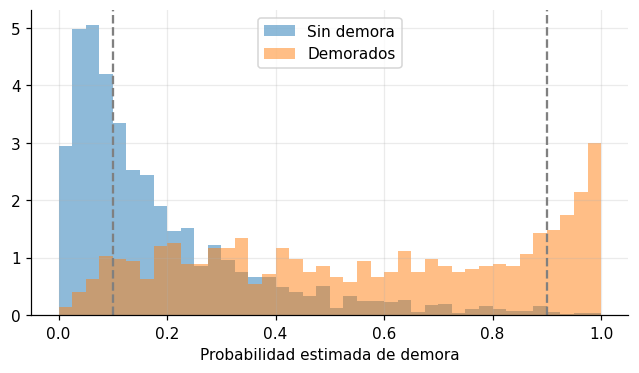

ninguna    : demorados descartados = 0 (0%)
[0.1, 0.9] : demorados descartados = 236 (26%)
min-max    : demorados descartados = 47 (5%)


In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6)); bins = np.linspace(0, 1, 41)
ax.hist(ps.loc[ps.late == 0, 'e_hat'], bins=bins, alpha=.5, density=True, label='Sin demora')
ax.hist(ps.loc[ps.late == 1, 'e_hat'], bins=bins, alpha=.5, density=True, label='Demorados')
ax.axvline(.1, color='gray', ls='--'); ax.axvline(.9, color='gray', ls='--')
ax.set_xlabel('Probabilidad estimada de demora'); ax.legend(); plt.show()

def mascara_trimming(df, regla):
    e, tr = df.e_hat, df.late == 1
    if regla == '[0.1, 0.9]':
        return (e >= .1) & (e <= .9)
    if regla == 'min-max':
        return (~tr | (e <= e[~tr].max())) & (tr | (e >= e[tr].min()))
    return pd.Series(True, index=df.index)

for regla in ['ninguna', '[0.1, 0.9]', 'min-max']:
    keep = mascara_trimming(ps, regla); desc = ((ps.late == 1) & ~keep).sum()
    print(f'{regla:11s}: demorados descartados = {desc} ({desc / ps.late.sum():.0%})')

### 4.3 Paso 3: emparejar, estimar y verificar el balance

Una función hace todo el recorrido para un modelo del score y una regla de trimming: empareja cada demorado con el no demorado de **logit-score** más cercano (con reemplazo), estima el ATT y calcula las diferencias de medias estandarizadas (DME) **antes y después** del matching, con cada control ponderado por las veces que se usa.

In [20]:
BAL = ['center', 'peak', 'log_freq', 'tenure_months', 'basket_usd']

def psm(df, modelo, regla):
    d = df.copy()
    d['e_hat'] = modelos[modelo].predict(d); d['center_x_peak'] = d.center * d.peak
    d = d[mascara_trimming(d, regla)]
    lg = np.log(d.e_hat / (1 - d.e_hat)).to_numpy()
    tr = d.late.to_numpy() == 1
    j = cKDTree(lg[~tr][:, None]).query(lg[tr][:, None])[1]
    yt, yc = d.orders.to_numpy()[tr], d.orders.to_numpy()[~tr]
    K = np.bincount(j, minlength=(~tr).sum())
    cols = BAL + ['center_x_peak']
    full = df.assign(center_x_peak=df.center * df.peak)
    sd = np.sqrt(full.groupby('late')[cols].var().mean())
    B = d[cols].to_numpy()
    antes = (full.groupby('late')[cols].mean().diff().iloc[-1]) / sd
    despues = (B[tr].mean(0) - (B[~tr] * K[:, None]).sum(0) / K.sum()) / sd.to_numpy()
    return {'ATT estimado': np.mean(yt - yc[j]), 'ATT verdadero (conservados)': d.loc[d.late == 1, 'true_effect'].mean(),
            'demorados descartados': int(df.late.sum() - tr.sum()), 'máx. usos de un control': int(K.max()),
            'dme': pd.DataFrame({'Antes': antes.abs(), 'Después': np.abs(despues)}, index=cols)}

corridas = {(m, r): psm(ps, m, r) for m in ['correcto', 'mal especificado'] for r in ['ninguna', '[0.1, 0.9]']}
pd.DataFrame({k: {c: v[c] for c in ['ATT estimado', 'ATT verdadero (conservados)', 'demorados descartados', 'máx. usos de un control']}
              for k, v in corridas.items()}).T

ATT estimado  ATT verdadero (conservados)  \
correcto         ninguna           -1.689                       -1.867   
                 [0.1, 0.9]        -1.355                       -1.662   
mal especificado ninguna           -1.759                       -1.867   
                 [0.1, 0.9]        -1.694                       -1.829   

                             demorados descartados  máx. usos de un control  
correcto         ninguna                       0.0                     54.0  
                 [0.1, 0.9]                  236.0                     11.0  
mal especificado ninguna                       0.0                     52.0  
                 [0.1, 0.9]                  129.0                     19.0

**Cómo leerlo.** Mirá primero `ATT verdadero (conservados)`: con el trimming $[0{,}1;\,0{,}9]$ se descarta una parte de los demorados y el ATT verdadero *cambia*. **El trimming cambió la pregunta.** Después compará `ATT estimado` con ese valor. Y notá algo incómodo: en una muestra, el modelo mal especificado puede quedar más cerca del verdadero que el correcto. Es ruido (el desvío del PSM entre muestras ronda 0,3), y en un análisis real ni siquiera conocés el valor verdadero. Por eso el diagnóstico es el **balance**.

### El love plot

Comparamos las DME de los dos modelos, sin trimming. Los puntos verdes dentro de la banda $|DME|<0{,}1$ son balance aceptable.

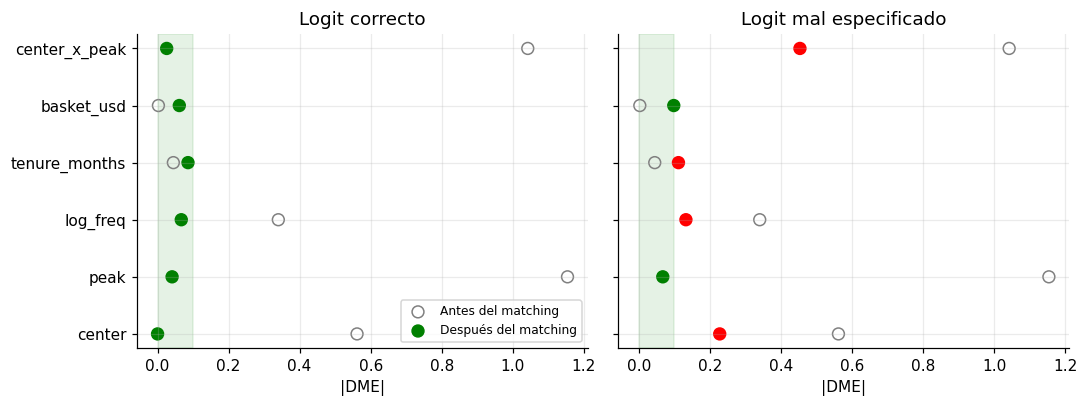

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, modelo in zip(axes, ['correcto', 'mal especificado']):
    dme = corridas[(modelo, 'ninguna')]['dme']; y = np.arange(len(dme))
    ax.axvspan(0, .1, color='green', alpha=.1)
    ax.scatter(dme['Antes'], y, facecolors='none', edgecolors='gray', s=60, label='Antes del matching')
    ax.scatter(dme['Después'], y, color=np.where(dme['Después'] > .1, 'red', 'green'), s=60, label='Después del matching')
    ax.set_yticks(y); ax.set_yticklabels(dme.index); ax.invert_yaxis(); ax.set_title(f'Logit {modelo}'); ax.set_xlabel('|DME|')
axes[0].legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

**Cómo leerlo.** Con el modelo correcto, todos los puntos llenos quedan dentro de la banda verde. Con el que omite la interacción, la interacción y la ubicación en el centro quedan **fuera**: el error del modelo se ve en el balance, aunque los dos logits tengan un pseudo-$R^2$ parecido. Es el diagnóstico que no depende de conocer el efecto verdadero.

*Nota*: los errores estándar del PSM que tienen en cuenta que el score es estimado (Abadie e Imbens, 2016) no están implementados acá.

## 5. Happiness on Tap: ¿qué se acerca al experimento?

Extracto de Devoto, Duflo, Dupas, Parienté y Pons (2012). Las **variables fueron modificadas** para el ejercicio: no replica el paper. Aprovechamos que sabemos qué dice el experimento: la *oferta* de la promoción (`motivacion`) se asignó al azar. Como la conexión efectiva (`conectado`) es una decisión del hogar, la tratamos como si fuera selección en observables y matcheamos con el sexo, la edad y la alfabetización del jefe de hogar.

In [22]:
hot = pd.read_csv('https://raw.githubusercontent.com/rpasquini/econometrics_and_causality/master/happiness_on_tap_extract.csv')
hot['mujer'] = (hot.sexojefe == 2).astype(int)         # sexojefe toma valores 1 / 2
dh = hot.dropna().copy()
XH = ['mujer', 'edadjefe', 'jefesabeleer', 'jefesabeescribir']
yh = dh.pdiasfueaescuela.to_numpy(); th = dh.conectado.to_numpy() == 1
print(f'Hogares con datos completos: {len(dh)}  (conectados: {th.sum()}, no conectados: {(~th).sum()})')
dh.groupby('conectado')[XH + ['motivacion', 'pdiasfueaescuela']].mean().round(3)

Hogares con datos completos: 317  (conectados: 164, no conectados: 153)


,mujer,edadjefe,jefesabeleer,jefesabeescribir,motivacion,pdiasfueaescuela
conectado,,,,,,
0,0.124,47.608,0.752,0.732,0.190,61.625
1,0.110,46.872,0.689,0.677,0.866,58.101


In [23]:
resultados = {}
# 1) ingenuo y MCO
r0 = smf.ols('pdiasfueaescuela ~ conectado', dh).fit(cov_type='HC1'); resultados['Ingenuo'] = (r0.params['conectado'], r0.bse['conectado'])
r1 = smf.ols('pdiasfueaescuela ~ conectado + ' + '+'.join(XH), dh).fit(cov_type='HC1'); resultados['MCO con controles'] = (r1.params['conectado'], r1.bse['conectado'])
# 2) matching exacto por sexo del jefe
tab_h = tabla_matching(dh, y='pdiasfueaescuela', t='conectado', celda='mujer'); display(tab_h)
resultados['Matching exacto (sexo)'] = ((tab_h.peso_att * tab_h.delta).sum(), np.nan)
# 3) vecino más cercano (covariables estandarizadas)
Zh = ((dh[XH] - dh[XH].mean()) / dh[XH].std()).to_numpy()
a, s, _ = att_matching(yh[th], yh[~th], Zh[th], Zh[~th]); resultados['Vecino más cercano'] = (a, s)
# 4) propensity score
mh = smf.logit('conectado ~ ' + '+'.join(XH), dh).fit(disp=0); e_h = mh.predict(dh).to_numpy(); lgh = np.log(e_h / (1 - e_h))[:, None]
a, s, _ = att_matching(yh[th], yh[~th], lgh[th], lgh[~th]); resultados['Propensity score'] = (a, s)
print(f'Pseudo-R2 del logit de la conexión: {mh.prsquared:.3f};  scores entre {e_h.min():.2f} y {e_h.max():.2f}')

,media_trat,n_trat,media_control,n_control,delta,peso_att,peso_ate
mujer,,,,,,,
0,58.317,146,61.407,134,-3.090,0.89,0.883
1,56.349,18,63.158,19,-6.809,0.11,0.117


Pseudo-R2 del logit de la conexión: 0.007;  scores entre 0.37 y 0.64


### El benchmark experimental

La oferta (`motivacion`) fue aleatoria. Su efecto sobre la asistencia es el **ITT**. Dividido por el efecto de la oferta sobre la conexión (la primera etapa) se obtiene el estimador de **Wald** (variables instrumentales; lo vemos en el Día 8). Como en el Día 5, la primera etapa se estima con la muestra completa.

,efecto (pp),error estándar
Ingenuo,-3.524,2.877
MCO con controles,-3.133,2.888
Matching exacto (sexo),-3.498,NaN
Vecino más cercano,-1.568,3.671
Propensity score,-7.666,3.682
Experimento: ITT,-4.641,2.854
Experimento: Wald,-7.769,4.778


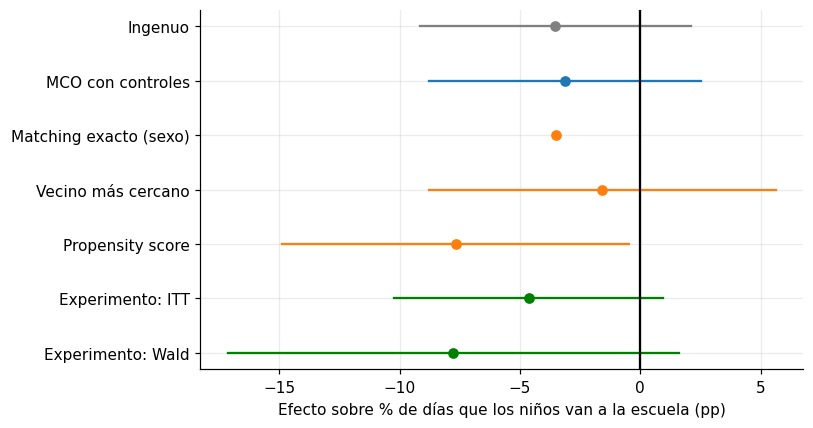

In [24]:
e0 = hot.dropna(subset=['pdiasfueaescuela'])
itt = smf.ols('pdiasfueaescuela ~ motivacion', e0).fit(cov_type='HC1')
pe = smf.ols('conectado ~ motivacion', hot).fit(cov_type='HC1')
resultados['Experimento: ITT'] = (itt.params['motivacion'], itt.bse['motivacion'])
resultados['Experimento: Wald'] = (itt.params['motivacion'] / pe.params['motivacion'], itt.bse['motivacion'] / pe.params['motivacion'])
tabla_res = pd.DataFrame(resultados, index=['efecto (pp)', 'error estándar']).T
display(tabla_res)

fig, ax = plt.subplots(figsize=(7.5, 4)); nombres = list(resultados)
for i, nom in enumerate(nombres):
    est, se = resultados[nom]; yy = len(nombres) - 1 - i
    col = 'green' if nom.startswith('Exp') else ('gray' if nom == 'Ingenuo' else 'tab:blue' if nom.startswith('MCO') else 'tab:orange')
    ax.plot(est, yy, 'o', color=col)
    if not np.isnan(se): ax.plot([est - 1.96 * se, est + 1.96 * se], [yy, yy], color=col)
ax.axvline(0, color='k'); ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres[::-1]); ax.set_xlabel('Efecto sobre % de días que los niños van a la escuela (pp)'); plt.tight_layout(); plt.show()

**Cómo leerlo.**

- Las covariables **casi no predicen** la conexión (pseudo-$R^2$ cercano a 0, scores entre 0,37 y 0,64). El soporte común es perfecto *porque* $X$ no contiene información sobre quién se conecta.
- Los estimadores observacionales van de valores muy dispares y **todos los intervalos incluyen al experimento**: con $n$ chico el ruido domina. Matchear cambia el punto, no la precisión.
- La selección relevante (qué hogares deciden conectarse) es probablemente **inobservable** (motivación de la familia). El matching no puede ver lo que $X$ no contiene. Lo que sí identifica es la **oferta aleatoria**, que es lo que usa el Wald.

## 6. LaLonde (1986) y Dehejia–Wahba (1999)

El **National Supported Work (NSW)** fue un programa de empleo en EE.UU. con asignación **aleatoria**. LaLonde se preguntó: si descartamos el grupo de control del experimento y lo reemplazamos por una muestra **observacional** (PSID o CPS), ¿los métodos econométricos recuperan el efecto experimental? Dehejia y Wahba mostraron que con propensity score, y una submuestra con el ingreso de los dos años previos, sí. Smith y Todd mostraron que el resultado es sensible a la muestra y a la especificación. Acá lo replicamos.

In [25]:
U = 'https://users.nber.org/~rdehejia/data/'
nsw = pd.read_stata(U + 'nsw_dw.dta'); psid = pd.read_stata(U + 'psid_controls.dta'); cps = pd.read_stata(U + 'cps_controls.dta')
print('NSW:', nsw.shape, ' PSID:', psid.shape, ' CPS:', cps.shape)
nsw.head()

NSW: (445, 11)  PSID: (2490, 11)  CPS: (15992, 11)


,data_id,treat,age,education,black,hispanic,married,nodegree,re74,re75,re78
0,Dehejia-Wahba Sample,1.0,37.0,11.0,1.0,0.0,1.0,1.0,0.0,0.0,9930.046
1,Dehejia-Wahba Sample,1.0,22.0,9.0,0.0,1.0,0.0,1.0,0.0,0.0,3595.894
2,Dehejia-Wahba Sample,1.0,30.0,12.0,1.0,0.0,0.0,0.0,0.0,0.0,24909.449
3,Dehejia-Wahba Sample,1.0,27.0,11.0,1.0,0.0,0.0,1.0,0.0,0.0,7506.146
4,Dehejia-Wahba Sample,1.0,33.0,8.0,1.0,0.0,0.0,1.0,0.0,0.0,289.790


Variables: `treat` (participó en el programa), `age`, `education`, `black`, `hispanic`, `married`, `nodegree` (sin título secundario), `re74` y `re75` (ingreso real de 1974 y 1975, **antes** del programa) y `re78` (ingreso de 1978, el resultado).

### 6.1 El benchmark experimental

In [26]:
trat, ctrl = nsw[nsw.treat == 1], nsw[nsw.treat == 0]
exp_att = trat.re78.mean() - ctrl.re78.mean()
exp_se = np.sqrt(trat.re78.var() / len(trat) + ctrl.re78.var() / len(ctrl))
print(f'Tratados: n={len(trat)}, ingreso 1978 = {trat.re78.mean():,.0f}   Controles: n={len(ctrl)}, ingreso 1978 = {ctrl.re78.mean():,.0f}')
print(f'Efecto experimental = {exp_att:,.0f}  (EE {exp_se:,.0f})')
COV = ['age', 'education', 'black', 'hispanic', 'married', 'nodegree', 're74', 're75']
pd.DataFrame({'NSW tratados': trat[COV].mean(), 'NSW controles': ctrl[COV].mean(),
              'PSID': psid[psid.treat == 0][COV].mean(), 'CPS': cps[cps.treat == 0][COV].mean()}).round(2)

Tratados: n=185, ingreso 1978 = 6,349   Controles: n=260, ingreso 1978 = 4,555
Efecto experimental = 1,794  (EE 671)


,NSW tratados,NSW controles,PSID,CPS
age,25.82,25.05,34.85,33.23
education,10.35,10.09,12.12,12.03
black,0.84,0.83,0.25,0.07
hispanic,0.06,0.11,0.03,0.07
married,0.19,0.15,0.87,0.71
nodegree,0.71,0.83,0.31,0.30
re74,2095.57,2107.03,19428.75,14016.80
re75,1532.06,1266.91,19063.34,13650.80


En el experimento los grupos se parecen (balance por aleatorización). Los controles de **PSID y CPS** son muy distintos: más viejos, casados, con ingresos previos de USD 14.000 a 19.000 frente a 2.000 de los participantes. Es un caso extremo de **falta de soporte común**.

### 6.2 Estimaciones con controles observacionales

In [27]:
F_OLS = 're78 ~ treat + age + I(age**2) + education + black + hispanic + married + nodegree + re74 + re75'
F_PS = 'treat ~ age + I(age**2) + education + black + hispanic + married + nodegree + re74 + re75 + I(re74==0) + I(re75==0)'

def estimar_nsw(controles):
    d = pd.concat([trat, controles[controles.treat == 0]], ignore_index=True)
    y = d.re78.to_numpy(); tr = d.treat.to_numpy() == 1
    ing = y[tr].mean() - y[~tr].mean(); ing_se = np.sqrt(y[tr].var(ddof=1) / tr.sum() + y[~tr].var(ddof=1) / (~tr).sum())
    mco = smf.ols(F_OLS, d).fit(cov_type='HC1')
    pm = smf.logit(F_PS, d).fit(disp=0, maxiter=300); e = np.clip(pm.predict(d).to_numpy(), 1e-6, 1 - 1e-6); lg = np.log(e / (1 - e))[:, None]
    Zs = ((d[COV] - d[COV].mean()) / d[COV].std()).to_numpy()
    a_nn, s_nn, _ = att_matching(y[tr], y[~tr], Zs[tr], Zs[~tr])
    a_ps, s_ps, K = att_matching(y[tr], y[~tr], lg[tr], lg[~tr])
    return d, e, tr, K, pd.DataFrame({'efecto': [ing, mco.params['treat'], a_nn, a_ps], 'EE': [ing_se, mco.bse['treat'], s_nn, s_ps]},
                                     index=['Ingenuo', 'MCO con controles', 'Vecino más cercano (covariables)', 'Propensity score'])

d_psid, e_psid, tr_psid, K_psid, res_psid = estimar_nsw(psid)
d_cps, e_cps, tr_cps, K_cps, res_cps = estimar_nsw(cps)
print(f'Benchmark experimental: {exp_att:,.0f}  (EE {exp_se:,.0f})')
pd.concat({'Controles PSID': res_psid, 'Controles CPS': res_cps}, axis=1).round(0)

Benchmark experimental: 1,794  (EE 671)


Controles PSID         Controles CPS       
                                         efecto      EE        efecto     EE
Ingenuo                                -15205.0   657.0       -8498.0  583.0
MCO con controles                         795.0   780.0         794.0  619.0
Vecino más cercano (covariables)           56.0  1328.0        2176.0  713.0
Propensity score                         1648.0  1128.0        2027.0  846.0

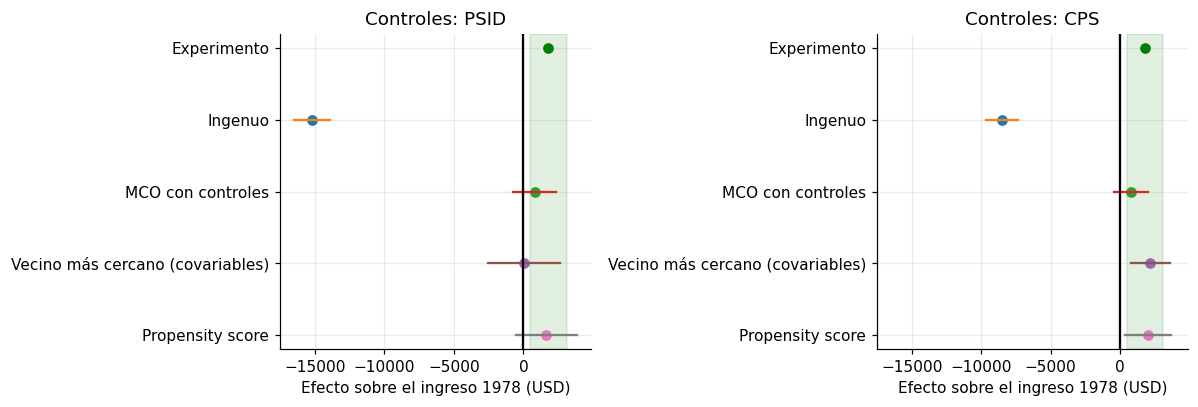

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, res, ttl in zip(axes, [res_psid, res_cps], ['Controles: PSID', 'Controles: CPS']):
    ax.axvspan(exp_att - 1.96 * exp_se, exp_att + 1.96 * exp_se, color='green', alpha=.12)
    for i, (nom, r) in enumerate(res.iterrows()):
        ax.plot(r.efecto, i + 1, 'o'); ax.plot([r.efecto - 1.96 * r.EE, r.efecto + 1.96 * r.EE], [i + 1, i + 1])
    ax.plot(exp_att, 0, 'o', color='green'); ax.axvline(0, color='k')
    ax.set_yticks(range(5)); ax.set_yticklabels(['Experimento'] + list(res.index)); ax.invert_yaxis(); ax.set_title(ttl); ax.set_xlabel('Efecto sobre el ingreso 1978 (USD)')
plt.tight_layout(); plt.show()

**Cómo leerlo.**

- La comparación ingenua se equivoca en el **signo** y por miles de dólares (el programa parecería *reducir* el ingreso).
- Con el **ingreso previo** como covariable, las estimaciones pasan a valores positivos y el PSM cae dentro del IC del experimento. Lo que importa es **qué se controla**: quién se enrola en un programa de empleo depende de su historia laboral reciente.
- Los estimadores **no coinciden entre sí** (el vecino más cercano sobre las covariables con PSID es mucho menor): el soporte común es pobre y el resultado es frágil ante la especificación.

### 6.3 Soporte común y balance (control: PSID)

Controles PSID con score < 0.01: 82%;  controles usados como match: 2%;  máximo de usos de un control: 24


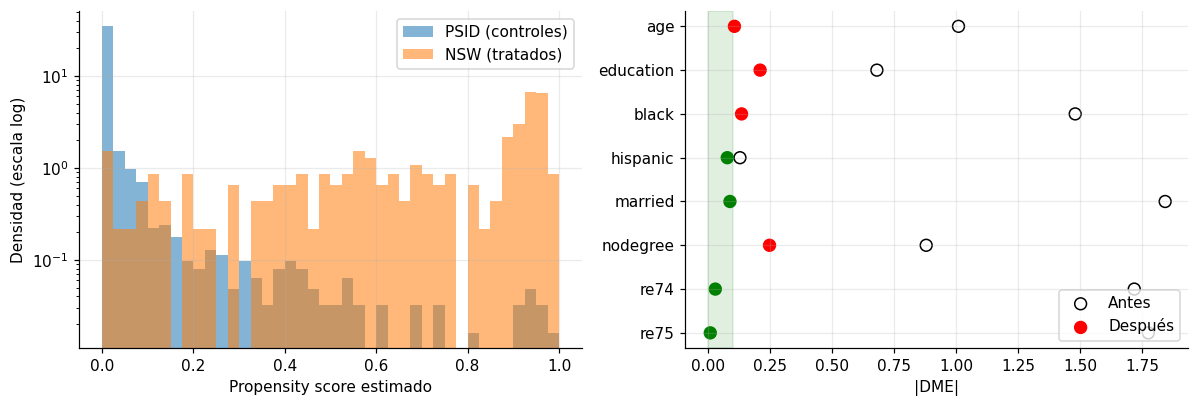

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0, 1, 41)
axes[0].hist(e_psid[~tr_psid], bins, alpha=.55, density=True, label='PSID (controles)'); axes[0].hist(e_psid[tr_psid], bins, alpha=.55, density=True, label='NSW (tratados)')
axes[0].set_yscale('log'); axes[0].set_xlabel('Propensity score estimado'); axes[0].set_ylabel('Densidad (escala log)'); axes[0].legend()
print(f'Controles PSID con score < 0.01: {(e_psid[~tr_psid] < .01).mean():.0%};  controles usados como match: {(K_psid > 0).mean():.0%};  máximo de usos de un control: {int(K_psid.max())}')

# Love plot: antes y después del PSM
lg = np.log(e_psid / (1 - e_psid)); j = cKDTree(lg[~tr_psid][:, None]).query(lg[tr_psid][:, None])[1]
filas = []
for c in COV:
    v = d_psid[c].to_numpy().astype(float); sd = np.sqrt((v[tr_psid].var(ddof=1) + v[~tr_psid].var(ddof=1)) / 2)
    filas.append((c, abs(v[tr_psid].mean() - v[~tr_psid].mean()) / sd, abs(v[tr_psid].mean() - v[~tr_psid][j].mean()) / sd))
bal = pd.DataFrame(filas, columns=['variable', 'antes', 'despues']).set_index('variable'); y = np.arange(len(bal))
axes[1].axvspan(0, .1, color='green', alpha=.12)
axes[1].scatter(bal.antes, y, facecolors='none', edgecolors='k', s=60, label='Antes'); axes[1].scatter(bal.despues, y, color=np.where(bal.despues > .1, 'red', 'green'), s=60, label='Después')
axes[1].set_yticks(y); axes[1].set_yticklabels(bal.index); axes[1].invert_yaxis(); axes[1].set_xlabel('|DME|'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

**Moraleja.** El matching puede funcionar cuando $X$ contiene lo que determinó la selección y hay soporte común. Esas son condiciones **sustantivas** que hay que argumentar y diagnosticar. Haber recuperado el experimento acá no garantiza que se lo recupere en otro contexto, y solo podemos compararlo porque el experimento *existe*.

## 7. Resumen

- **Matching exacto**: un `groupby` alcanza; el ATT es un promedio ponderado de diferencias dentro de celdas. La regresión con dummies pondera distinto; la interactuada recupera el ATT.
- **Vecino más cercano**: con varias características continuas el sesgo decae como $N^{-1/k}$; corregilo con una regresión y usá los errores estándar de Abadie–Imbens, no el bootstrap.
- **PSM**: estimá el score, mirá el soporte común, reportá qué cambió con el trimming y juzgá el modelo por el **balance**.
- El matching **no corrige inobservables**: la credibilidad del CIA es un argumento sustantivo.

## 8. Ejercicios

1. **Segmentos.** Con `seg_het`, calculá a mano el ATT, el ATE y el coeficiente de MCO con dummies usando la tabla de matching y los pesos de la sección 1.3. ¿Qué segmento domina en cada caso?
2. **Soporte común.** Eliminá los *demorados* del segmento D en `seg_het`. ¿Cambian el ATT y el ATE? ¿Por qué el ATT cambia menos?
3. **Dale y Krueger.** Agregá un tercer grupo E con tres estudiantes (dos que eligieron privadas y uno una pública) con ingresos que vos elijas. Recalculá el ATT.
4. **Dimensionalidad.** En 3.2, ¿cuántas veces más datos hacen falta con $k=4$ para reducir la distancia a la mitad? Verificalo con la simulación.
5. **Cobertura.** Repetí la simulación de 3.3 con $k=1$ y con $k=4$. ¿Para qué $k$ el matching simple tiene buena cobertura?
6. **Corrección de sesgo.** Cambiá $\mu_0(x)=\sum_k x_k$ por una función curva (por ejemplo $\sum_k x_k^2$ o $\sum_k\sin x_k$). ¿Sigue funcionando la corrección lineal? ¿Y la imputación por regresión?
7. **PSM.** Aplicá un *caliper* (descartá los pares cuyo logit-score difiere más de 0,2 desvíos). ¿Qué pasa con el ATT estimado y con el verdadero de los conservados?
8. **Happiness on Tap.** ¿Qué covariable adicional, *previa* al tratamiento, harías que el CIA para la conexión sea más creíble? ¿Hay alguna en la base?
9. **NSW.** Repetí el PSM sin `re74` y `re75`. ¿Qué le pasa a la estimación y al balance? ¿Qué te dice sobre qué hace creíble el CIA?